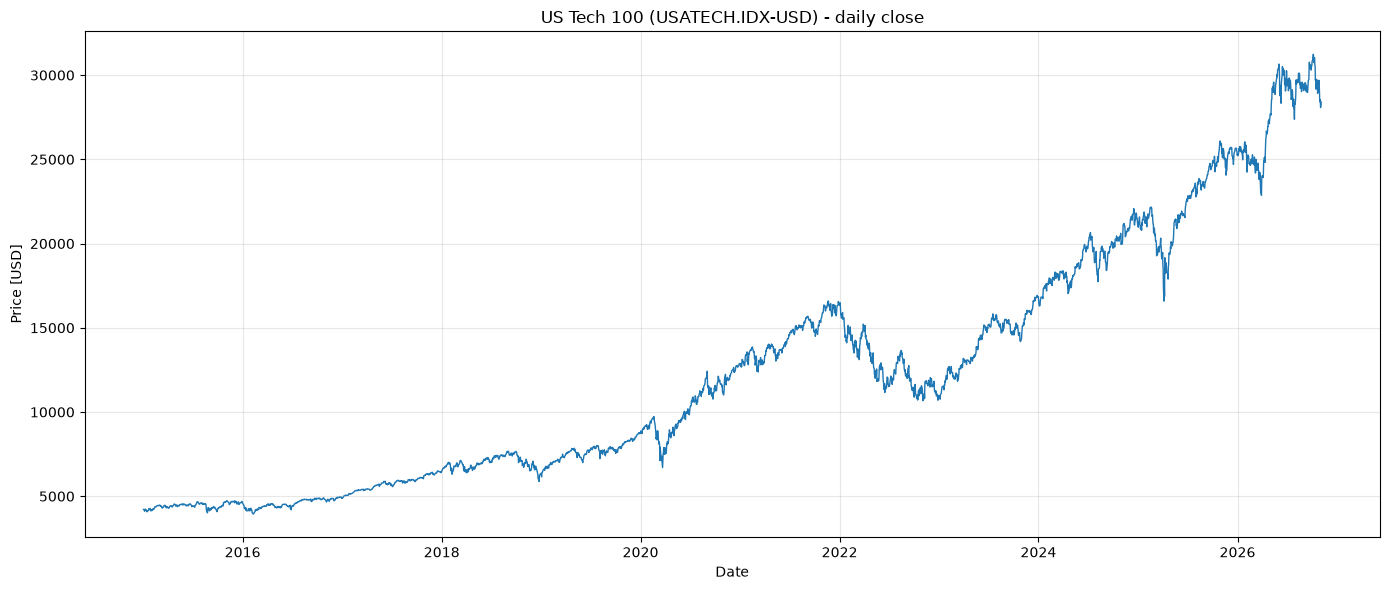

In [1]:
import matplotlib.pyplot as plt
from dukascopy_downloader import load

# daily candles of US Tech 100 (Nasdaq) built from the stored 1-minute data
df = load("../data", "USATECH.IDX-USD", "m1", resample="1D", drop_flat=True)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df["time"], df["close"], linewidth=1)
ax.set_title("US Tech 100 (USATECH.IDX-USD) - daily close")
ax.set_xlabel("Date")
ax.set_ylabel("Price [USD]")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## All downloaded symbols - daily close

In [2]:
from pathlib import Path
import math
import pandas as pd

DATA = Path("../data")

# every symbol with stored 1-minute data, as daily closes
codes = sorted(p.parent.name for p in (DATA / "m1").rglob("BID"))
closes = {}
for c in codes:
    d = load(DATA, c, "m1", resample="1D", drop_flat=True)
    if not d.empty:
        closes[c] = d.set_index(d["time"].dt.tz_localize(None))["close"]
print(f"{len(closes)} symbols loaded")

55 symbols loaded


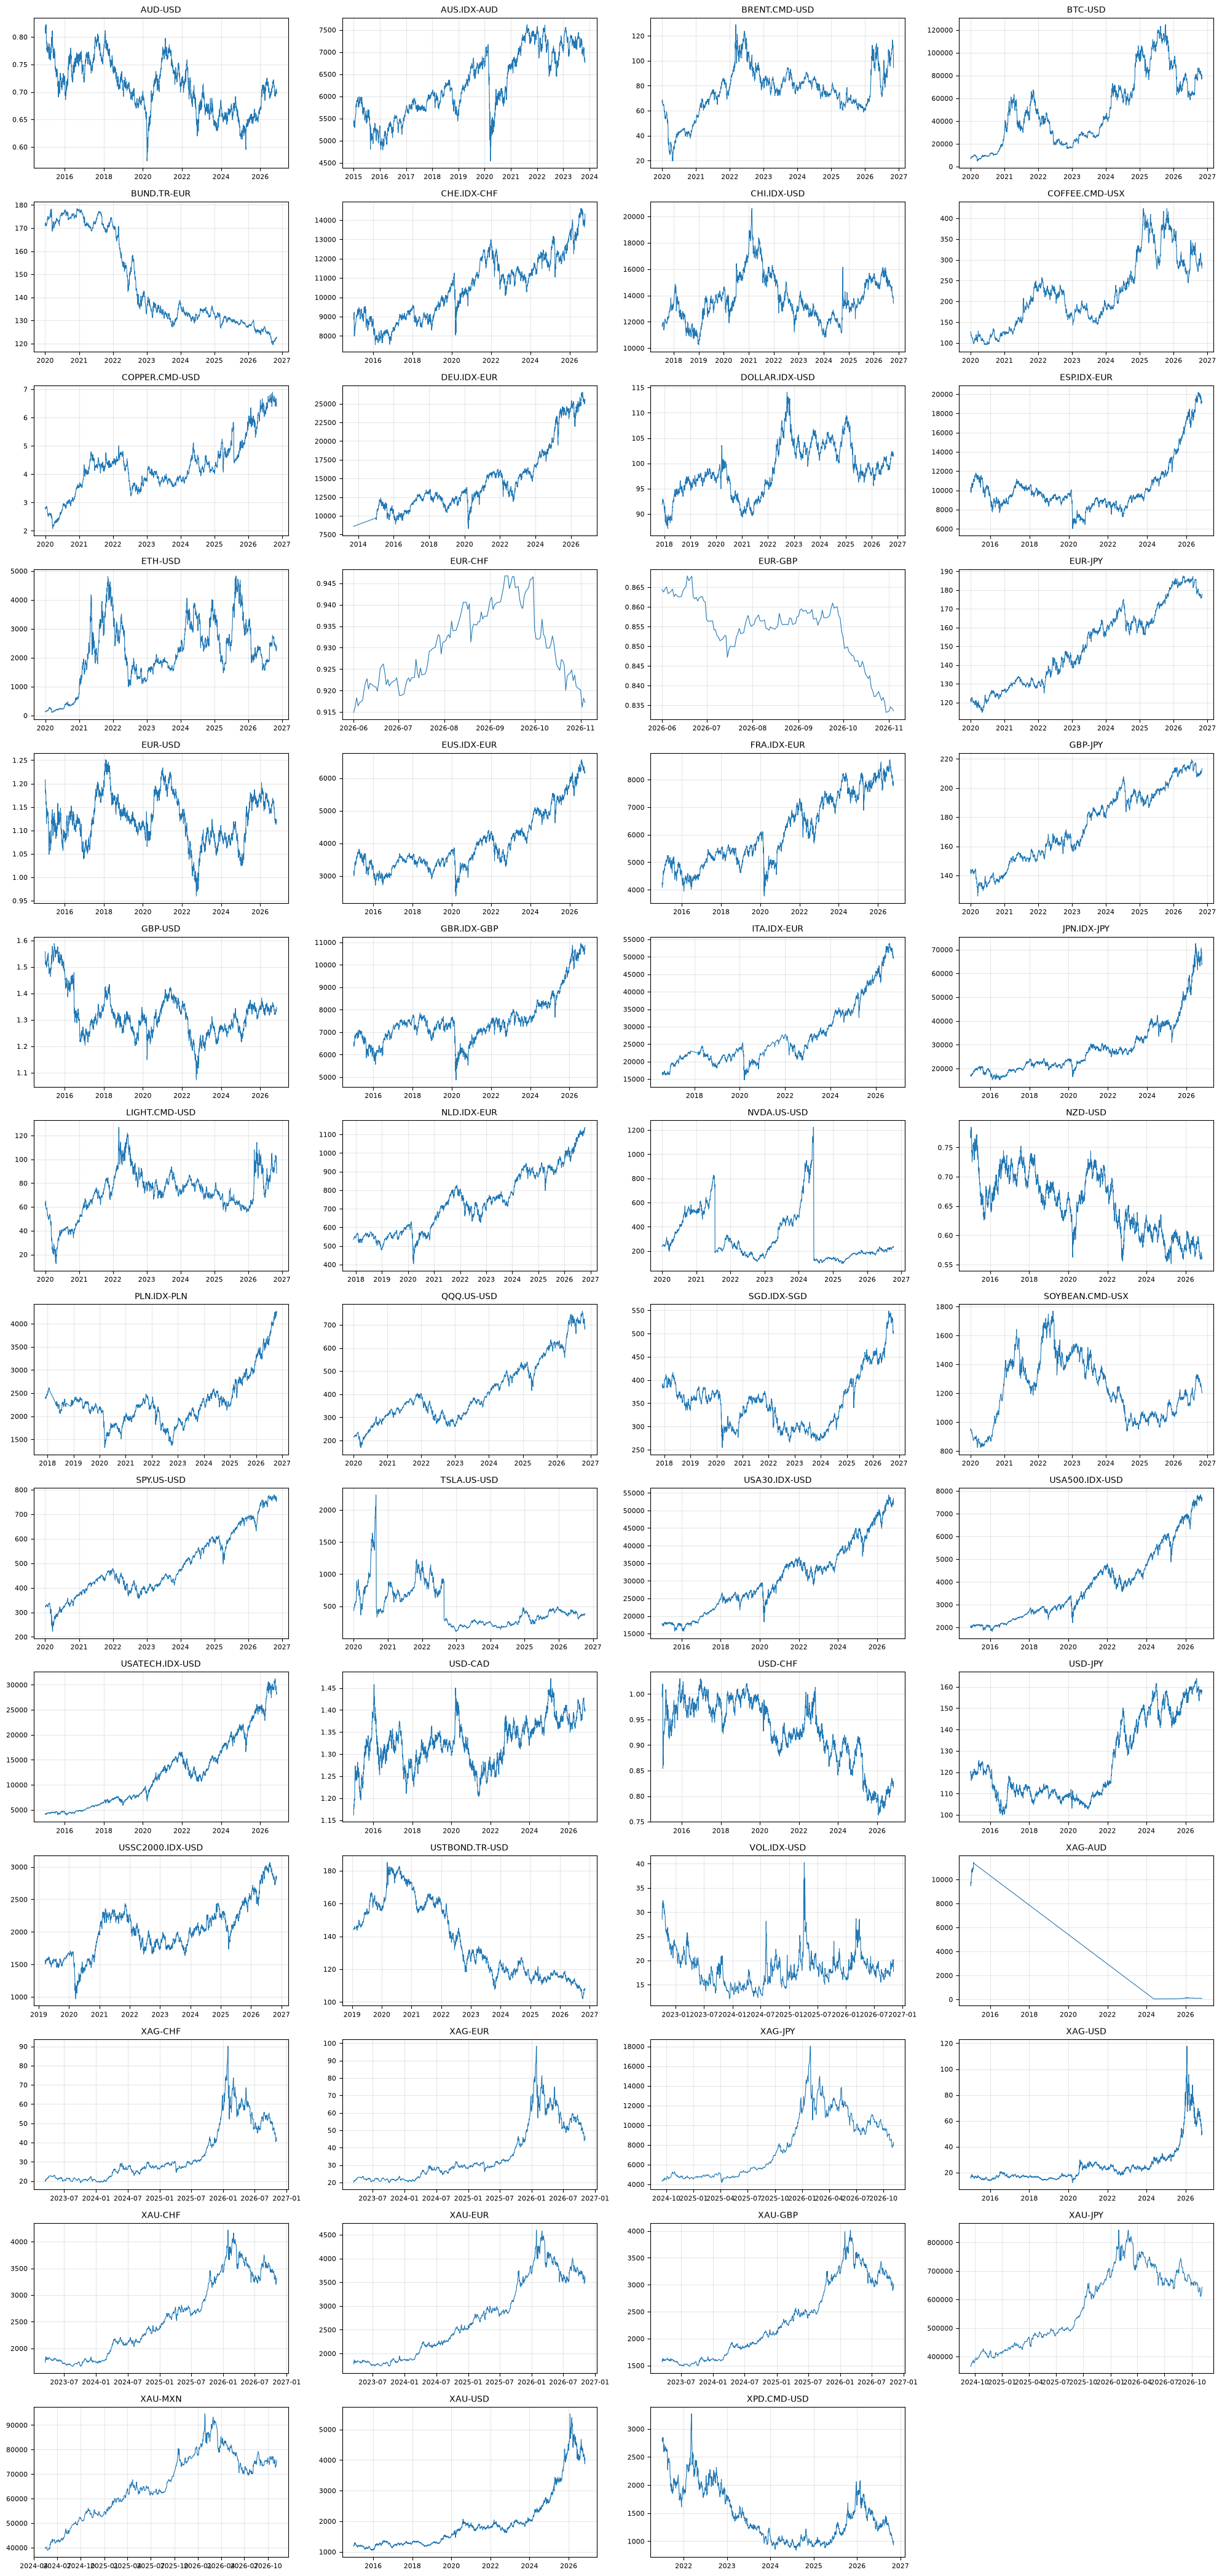

In [3]:
cols = 4
rows = math.ceil(len(closes) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(20, 3 * rows))
for ax, (c, s) in zip(axes.flat, closes.items()):
    ax.plot(s.index, s.values, linewidth=0.8)
    ax.set_title(c, fontsize=10)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=8)
for ax in axes.flat[len(closes):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## Check against reference data (Yahoo Finance)

Dukascopy prices are CFD/spot quotes, the references are cash indices, futures or exchange prices,
so small differences are expected (futures premium, different close time). What matters is that
the ratio Dukascopy / reference stays close to 1 and has no jumps.

In [4]:
import numpy as np
import yfinance as yf

# reference for each symbol: list of (Yahoo ticker, exponent), the product gives the price
REF = {
    "AUD-USD": [("AUDUSD=X", 1)], "EUR-USD": [("EURUSD=X", 1)], "GBP-USD": [("GBPUSD=X", 1)],
    "NZD-USD": [("NZDUSD=X", 1)], "USD-CAD": [("CAD=X", 1)], "USD-CHF": [("CHF=X", 1)],
    "USD-JPY": [("JPY=X", 1)], "EUR-CHF": [("EURCHF=X", 1)], "EUR-GBP": [("EURGBP=X", 1)],
    "EUR-JPY": [("EURJPY=X", 1)], "GBP-JPY": [("GBPJPY=X", 1)],
    "XAU-USD": [("GC=F", 1)], "XAG-USD": [("SI=F", 1)],
    "XAU-EUR": [("GC=F", 1), ("EURUSD=X", -1)], "XAU-GBP": [("GC=F", 1), ("GBPUSD=X", -1)],
    "XAU-CHF": [("GC=F", 1), ("CHF=X", 1)], "XAU-JPY": [("GC=F", 1), ("JPY=X", 1)],
    "XAU-MXN": [("GC=F", 1), ("MXN=X", 1)],
    "XAG-EUR": [("SI=F", 1), ("EURUSD=X", -1)], "XAG-AUD": [("SI=F", 1), ("AUDUSD=X", -1)],
    "XAG-CHF": [("SI=F", 1), ("CHF=X", 1)], "XAG-JPY": [("SI=F", 1), ("JPY=X", 1)],
    "XPD.CMD-USD": [("PA=F", 1)], "COPPER.CMD-USD": [("HG=F", 1)],
    "BRENT.CMD-USD": [("BZ=F", 1)], "LIGHT.CMD-USD": [("CL=F", 1)],
    "COFFEE.CMD-USX": [("KC=F", 1)], "SOYBEAN.CMD-USX": [("ZS=F", 1)],
    "USTBOND.TR-USD": [("ZB=F", 1)],
    "BTC-USD": [("BTC-USD", 1)], "ETH-USD": [("ETH-USD", 1)],
    "USA30.IDX-USD": [("^DJI", 1)], "USA500.IDX-USD": [("^GSPC", 1)], "USATECH.IDX-USD": [("^NDX", 1)],
    "USSC2000.IDX-USD": [("^RUT", 1)], "VOL.IDX-USD": [("^VIX", 1)], "DOLLAR.IDX-USD": [("DX-Y.NYB", 1)],
    "DEU.IDX-EUR": [("^GDAXI", 1)], "FRA.IDX-EUR": [("^FCHI", 1)], "GBR.IDX-GBP": [("^FTSE", 1)],
    "ESP.IDX-EUR": [("^IBEX", 1)], "EUS.IDX-EUR": [("^STOXX50E", 1)], "ITA.IDX-EUR": [("FTSEMIB.MI", 1)],
    "NLD.IDX-EUR": [("^AEX", 1)], "CHE.IDX-CHF": [("^SSMI", 1)],
    "JPN.IDX-JPY": [("^N225", 1)], "AUS.IDX-AUD": [("^AXJO", 1)],
    "SPY.US-USD": [("SPY", 1)], "QQQ.US-USD": [("QQQ", 1)], "NVDA.US-USD": [("NVDA", 1)], "TSLA.US-USD": [("TSLA", 1)],
}

tickers = sorted({t for v in REF.values() for t, _ in v})
yahoo = yf.download(tickers, start="2013-01-01", progress=False, auto_adjust=False)["Close"]
yahoo.index = pd.to_datetime(yahoo.index).tz_localize(None).normalize()
# Yahoo labels a forex day by the day it ends, Dukascopy by the day it starts
for t in yahoo.columns:
    if t.endswith("=X"):
        yahoo[t] = yahoo[t].shift(-1)

refs, rows = {}, []
for c, s in closes.items():
    if c not in REF:
        continue
    r = math.prod(yahoo[t] ** e for t, e in REF[c])
    j = pd.concat([s.rename("duka"), r.rename("ref")], axis=1, sort=True).dropna()
    j = j[(j > 0).all(axis=1)]  # WTI went negative in April 2020
    if len(j) < 20:
        continue
    refs[c] = j
    ratio = j.duka / j.ref
    wk = np.log(j.resample("W-FRI").last()).diff().dropna()
    rows.append({
        "symbol": c, "reference": " * ".join(t for t, _ in REF[c]), "days": len(j),
        "ratio_median": ratio.median(), "ratio_min": ratio.min(), "ratio_max": ratio.max(),
        "median_dev_%": np.log(ratio / ratio.median()).abs().median() * 100,
        "weekly_return_corr": wk.duka.corr(wk.ref),
    })

summary = pd.DataFrame(rows).set_index("symbol").sort_values("median_dev_%", ascending=False)
summary.style.format(precision=4).background_gradient(subset=["median_dev_%"], cmap="Reds")

,reference,days,ratio_median,ratio_min,ratio_max,median_dev_%,weekly_return_corr
symbol,,,,,,,
NVDA.US-USD,NVDA,1702,9.9949,0.9968,40.0553,138.6256,0.3452
VOL.IDX-USD,^VIX,1025,1.0461,0.6733,1.2487,4.3204,0.8898
XAG-AUD,SI=F * AUDUSD=X,523,1.0008,0.8769,550.2203,0.6081,0.9304
XAG-JPY,SI=F * JPY=X,427,1.0001,0.8773,1.0795,0.6042,0.9433
COFFEE.CMD-USX,KC=F,1715,0.9976,0.8970,1.0324,0.5834,0.9575
XPD.CMD-USD,PA=F,1342,1.0044,0.9235,1.1021,0.5652,0.9867
JPN.IDX-JPY,^N225,2864,1.0005,0.9118,1.0964,0.4870,0.8552
COPPER.CMD-USD,HG=F,1723,1.0017,0.8327,1.0542,0.4327,0.9867
XAG-CHF,SI=F * CHF=X,727,0.9998,0.8772,1.0793,0.4002,0.9490


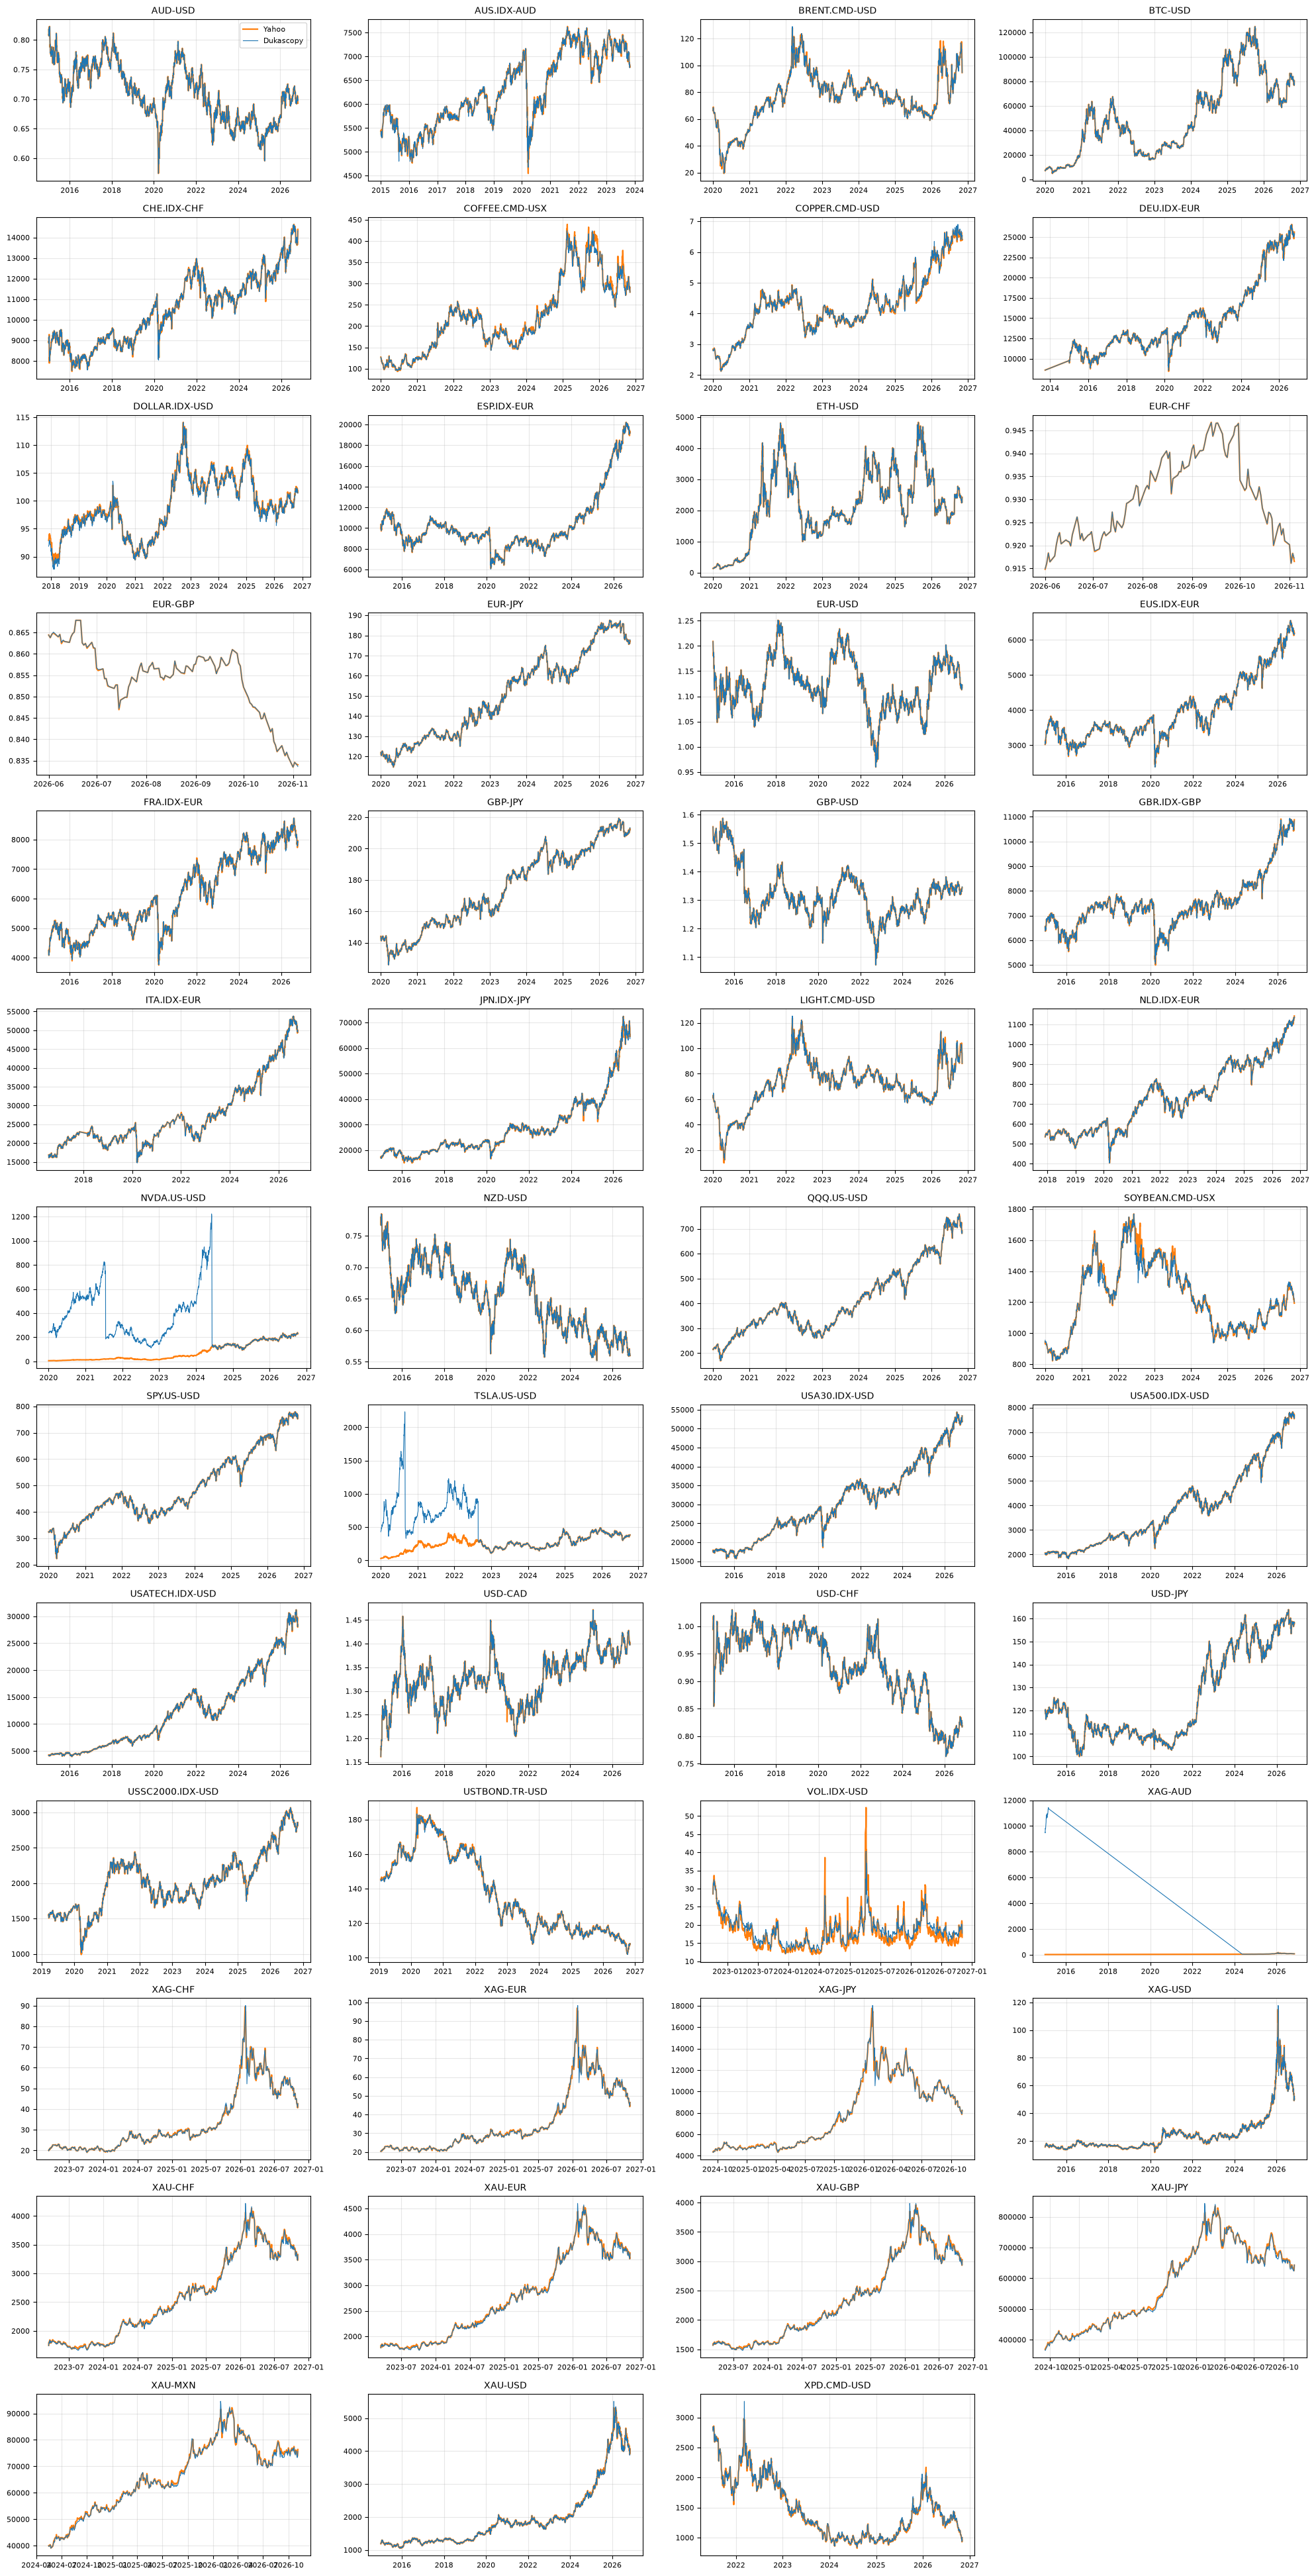

In [5]:
cols = 4
rows = math.ceil(len(refs) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(20, 3 * rows))
for ax, (c, j) in zip(axes.flat, refs.items()):
    ax.plot(j.index, j.ref, linewidth=1.6, color="tab:orange", label="Yahoo")
    ax.plot(j.index, j.duka, linewidth=0.8, color="tab:blue", label="Dukascopy")
    ax.set_title(c, fontsize=10)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=8)
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(refs):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()